# Stock Price Prediction

Required few steps before running this:

```py
python -m pip install scikit-learn
python -m pip install seaborn
python -m pip isntall matplotlib
python -m pip install kaggle
python -m pip install yfinance
```

---

Challenge: Not a Challenge \
Datasets: Not a Competetion \

---

Written by Mohd Zaid (mdzaid0205@gmail.com)

In [ ]:
# # Not Required
# CONTESTS:str = "titanic"
# LOCATION:str = "./tmp/data"
# !kaggle competitions download -c {CONTESTS} -p {LOCATION}
# !mkdir "{LOCATION}/{CONTESTS}"
# !tar -xf "{LOCATION}/{CONTESTS}.zip" -C "{LOCATION}/{CONTESTS}"

## Basic Imports and Loading File

In [131]:
import pandas as pd, numpy as np, os
import yfinance as yf, seaborn as sb
from matplotlib import pyplot as plt
from pathlib import Path
from typing import Optional

In [74]:
CAT1 = ["AAPL", "GOOGL", "MSFT", "META", "AMZN", ] 
CAT2 = ["NVDA", "AVGO", "AMD", "TSM", "INTC", "QCOM", ]
CAT3 = ["JPM", "BAC", "GS", "MS", "V", "MA", ]
CAT4 = ["ORCL", "CRM", "ADBE", "IBM", "SAP", ]
CAT5 = ["CSCO", "PANW", "CRWD", "ANET", ]
CAT6 = ["TSLA", "NFLX", "PLTR", "SHOP", ]

TICKERS = CAT1 + CAT2 + CAT3 + CAT4 + CAT5 + CAT6

LOCATION:str = "tmp/data/"
CONTESTS:str = "stock_price"


folder:Path = Path(LOCATION) / Path(CONTESTS)
folder.mkdir(parents=True, exist_ok=True)

for tick in TICKERS:
    data = yf.download(tick, period="10y", interval="1d", group_by="ticker")

    if data is not None:
        cutoff_date = data.index.max() - pd.DateOffset(years=2)
        
        train_split = data[data.index <= data.index.max() - pd.DateOffset(years=2)]
        tests_split = data[data.index  > data.index.max() - pd.DateOffset(years=2)]

        train_split.to_csv(folder / ("train-" + tick + ".csv"))
        tests_split.to_csv(folder / ("tests-" + tick + ".csv"))


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%********

In [343]:
OVERWRITE_TESTS_PATH: Optional[Path] = None     # Path("Path")  # tests.csv path
OVERWRITE_TRAIN_PATH: Optional[Path] = None     # Path("Path")  # train.csv path
OVERWRITE_FINAL_PATH: Optional[Path] = None     # Path("Path")  # output path

base_train_directory:Path = Path(LOCATION) / Path(CONTESTS)
base_tests_directory:Path = Path(LOCATION) / Path(CONTESTS)

if OVERWRITE_TRAIN_PATH and OVERWRITE_TRAIN_PATH.is_file():
    base_train_directory = OVERWRITE_TRAIN_PATH.parent.name

if OVERWRITE_TESTS_PATH and OVERWRITE_TESTS_PATH.is_file():
    base_tests_directory = OVERWRITE_TESTS_PATH.parent.name

TRAIN_FILENAMES:dict[str, str] = {t:"train-" + t + ".csv" for t in TICKERS}
TESTS_FILENAMES:dict[str, str] = {t:"tests-" + t + ".csv" for t in TICKERS}

train_filepaths:dict[str, Path] = {t:base_train_directory/TRAIN_FILENAMES[t] for t in TICKERS}
tests_filepaths:dict[str, Path] = {t:base_tests_directory/TESTS_FILENAMES[t] for t in TICKERS}

def find_filepath(required_filename:str, base_directory:Path) -> Path:
    for (directory, _, filenames) in os.walk(base_directory):
        if required_filename in filenames:
            return Path(directory) / Path(required_filename)
    return base_directory / Path(required_filename)

train_filepath:dict[str, Path] = {t:find_filepath(TRAIN_FILENAMES[t], base_train_directory) for t in TICKERS}
tests_filepath:dict[str, Path] = {t:find_filepath(TESTS_FILENAMES[t], base_tests_directory) for t in TICKERS}
final_filepath:Path = Path(LOCATION) / Path(CONTESTS) / 'submission.csv'

for ticker, file_paths in train_filepaths.items(): 
    assert file_paths.is_file() and file_paths.name == TRAIN_FILENAMES[ticker], f"{file_paths=} for {ticker=} is not valid file for training"


for ticker, file_paths in tests_filepaths.items(): 
    assert file_paths.is_file() and file_paths.name == TESTS_FILENAMES[ticker], f"{file_paths=} for {ticker=} is not valid file for training"

display(train_filepath)
display(tests_filepath)
display(final_filepath)

{'AAPL': WindowsPath('tmp/data/stock_price/train-AAPL.csv'),
 'GOOGL': WindowsPath('tmp/data/stock_price/train-GOOGL.csv'),
 'MSFT': WindowsPath('tmp/data/stock_price/train-MSFT.csv'),
 'META': WindowsPath('tmp/data/stock_price/train-META.csv'),
 'AMZN': WindowsPath('tmp/data/stock_price/train-AMZN.csv'),
 'NVDA': WindowsPath('tmp/data/stock_price/train-NVDA.csv'),
 'AVGO': WindowsPath('tmp/data/stock_price/train-AVGO.csv'),
 'AMD': WindowsPath('tmp/data/stock_price/train-AMD.csv'),
 'TSM': WindowsPath('tmp/data/stock_price/train-TSM.csv'),
 'INTC': WindowsPath('tmp/data/stock_price/train-INTC.csv'),
 'QCOM': WindowsPath('tmp/data/stock_price/train-QCOM.csv'),
 'JPM': WindowsPath('tmp/data/stock_price/train-JPM.csv'),
 'BAC': WindowsPath('tmp/data/stock_price/train-BAC.csv'),
 'GS': WindowsPath('tmp/data/stock_price/train-GS.csv'),
 'MS': WindowsPath('tmp/data/stock_price/train-MS.csv'),
 'V': WindowsPath('tmp/data/stock_price/train-V.csv'),
 'MA': WindowsPath('tmp/data/stock_price/tra

{'AAPL': WindowsPath('tmp/data/stock_price/tests-AAPL.csv'),
 'GOOGL': WindowsPath('tmp/data/stock_price/tests-GOOGL.csv'),
 'MSFT': WindowsPath('tmp/data/stock_price/tests-MSFT.csv'),
 'META': WindowsPath('tmp/data/stock_price/tests-META.csv'),
 'AMZN': WindowsPath('tmp/data/stock_price/tests-AMZN.csv'),
 'NVDA': WindowsPath('tmp/data/stock_price/tests-NVDA.csv'),
 'AVGO': WindowsPath('tmp/data/stock_price/tests-AVGO.csv'),
 'AMD': WindowsPath('tmp/data/stock_price/tests-AMD.csv'),
 'TSM': WindowsPath('tmp/data/stock_price/tests-TSM.csv'),
 'INTC': WindowsPath('tmp/data/stock_price/tests-INTC.csv'),
 'QCOM': WindowsPath('tmp/data/stock_price/tests-QCOM.csv'),
 'JPM': WindowsPath('tmp/data/stock_price/tests-JPM.csv'),
 'BAC': WindowsPath('tmp/data/stock_price/tests-BAC.csv'),
 'GS': WindowsPath('tmp/data/stock_price/tests-GS.csv'),
 'MS': WindowsPath('tmp/data/stock_price/tests-MS.csv'),
 'V': WindowsPath('tmp/data/stock_price/tests-V.csv'),
 'MA': WindowsPath('tmp/data/stock_price/tes

WindowsPath('tmp/data/stock_price/submission.csv')

In [ ]:
TRAINING_DATAS:dict[str, pd.DataFrame] = {}
TESTINGS_DATAS:dict[str, pd.DataFrame] = {}

def clean(df:pd.DataFrame) -> pd.DataFrame:
    df.columns = df.iloc[0]
    df = df.rename(columns={"Price":"Date"})
    df = df.iloc[2:].reset_index(drop=True)

    df["Date"] = pd.to_datetime(df["Date" ])
    df["Open" ] = pd.to_numeric(df["Open" ])
    df["Close"] = pd.to_numeric(df["Close"])
    df["High" ] = pd.to_numeric(df["High" ])
    df["Low"  ] = pd.to_numeric(df["Low"  ])
    df["Volume"] = pd.to_numeric(df["Volume"])

    df.columns.name = None
    return df

for ticker, train_filepath in train_filepaths.items():
    if os.path.exists(train_filepath) and train_filepath.is_file():
        TRAINING_DATAS[ticker] = clean(pd.read_csv(train_filepath))

for ticker, tests_filepath in tests_filepaths.items():
    if os.path.exists(tests_filepath) and tests_filepath.is_file():
        TESTINGS_DATAS[ticker] = clean(pd.read_csv(tests_filepath))


assert TRAINING_DATAS, "Please re-check training file path"
assert TESTINGS_DATAS, "Please re-check testings file path"

display(TICKERS[0])
display(TRAINING_DATAS[TICKERS[0]].head(5))
display(TESTINGS_DATAS[TICKERS[0]].head(5))


'AAPL'

,Date,Open,High,Low,Close,Volume
0,2016-10-17,26.831687,26.948315,26.705909,26.881998,94499600
1,2016-10-18,27.026069,27.032930,26.859128,26.863703,98214000
2,2016-10-19,26.813389,26.930020,26.024425,26.783661,80138400
3,2016-10-20,26.724205,26.843121,26.603002,26.769941,96503200
4,2016-10-21,26.712767,26.735637,26.591564,26.664743,92770800


,Date,Open,High,Low,Close,Volume
0,2024-10-17,231.493486,231.910015,228.607638,230.224106,32993800
1,2024-10-18,234.220680,234.220680,232.068684,233.050476,46431500
2,2024-10-21,232.505061,234.885160,232.505061,234.518219,36254500
3,2024-10-22,231.949677,234.260350,230.670386,233.903336,38846600
4,2024-10-23,232.138123,233.189327,225.870545,228.845657,52287000


In [345]:
display(TRAINING_DATAS[TICKERS[0]].info())
display(TESTINGS_DATAS[TICKERS[0]].info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2013 entries, 0 to 2012
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    2013 non-null   datetime64[ns]
 1   Open    2013 non-null   float64       
 2   High    2013 non-null   float64       
 3   Low     2013 non-null   float64       
 4   Close   2013 non-null   float64       
 5   Volume  2013 non-null   int64         
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 94.5 KB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 501 entries, 0 to 500
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    501 non-null    datetime64[ns]
 1   Open    501 non-null    float64       
 2   High    501 non-null    float64       
 3   Low     501 non-null    float64       
 4   Close   501 non-null    float64       
 5   Volume  501 non-null    int64         
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 23.6 KB


None

## Data Analysis

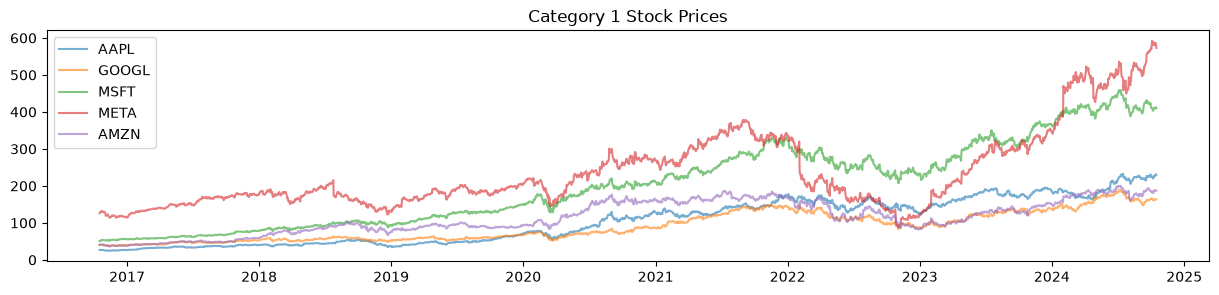

In [346]:
plt.figure(figsize=(15,3))
plt.title("Category 1 Stock Prices")
for tickers in CAT1:
    plt.plot(TRAINING_DATAS[tickers].Date, TRAINING_DATAS[tickers].Close, label=tickers, alpha=0.6)
plt.legend()

<BarContainer object of 30 artists>

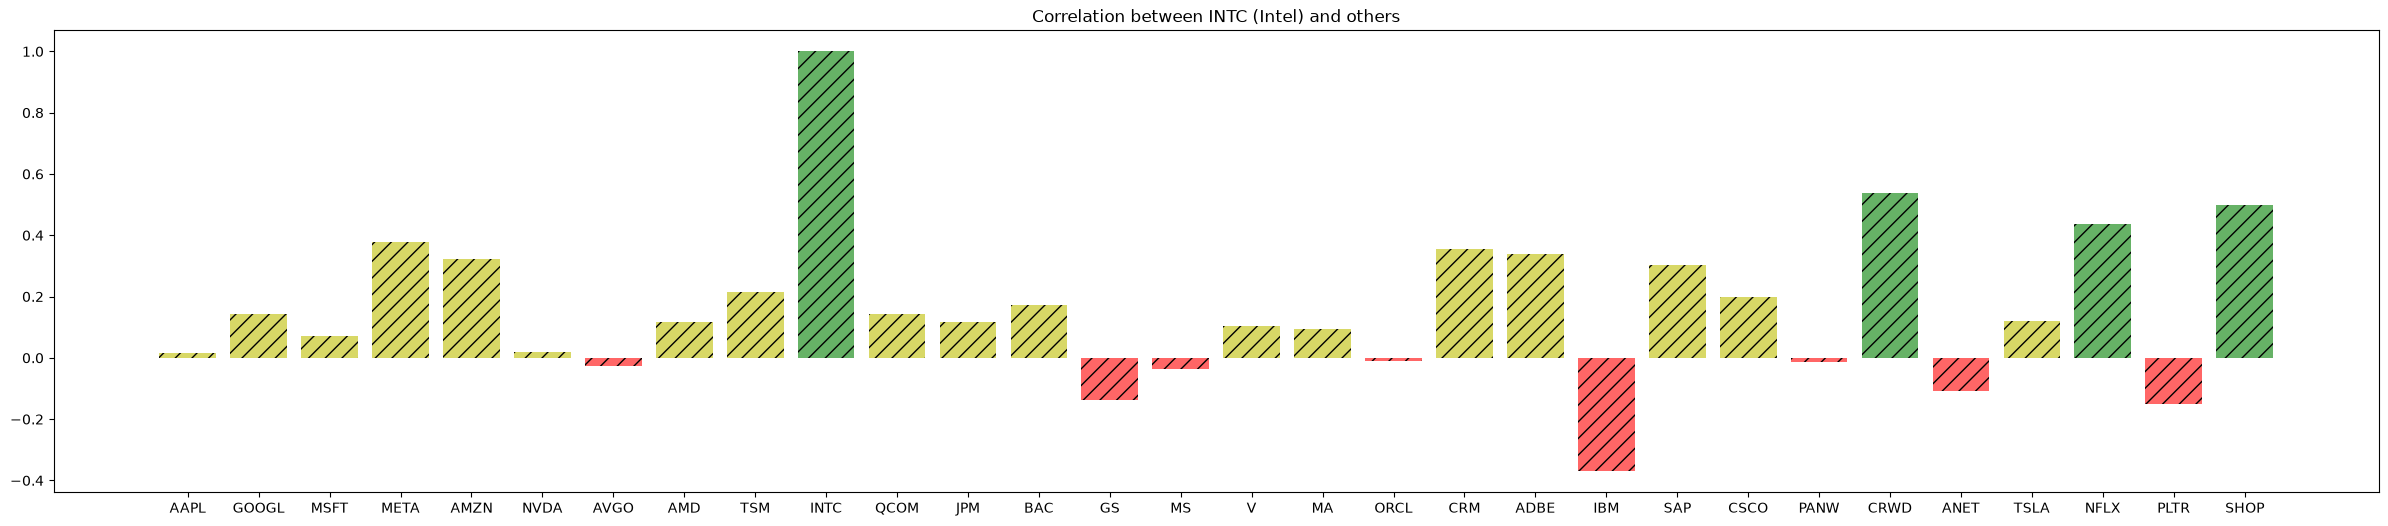

In [347]:
correlation:list[float] = []
corr_labels:list[str]   = []

for tickers in TICKERS:
    correlation.append(TRAINING_DATAS["INTC"]["Open"].corr(TRAINING_DATAS[tickers]["Open"], method="spearman"))
    corr_labels.append(tickers)

colors = ["g" if c > 0.4 else "y" if c >= 0 else "r" for c in correlation]

plt.figure(figsize=(30,6))
plt.title("Correlation between INTC (Intel) and others")
plt.bar(corr_labels, correlation, color=colors, alpha=0.6, hatch="//")

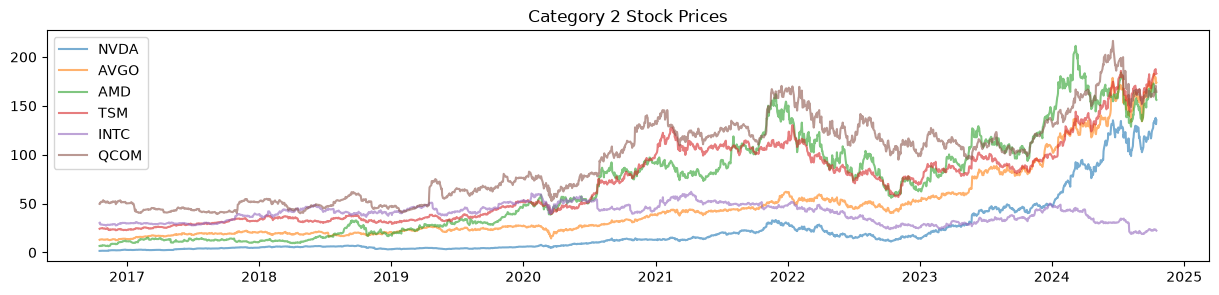

In [348]:
plt.figure(figsize=(15,3))
plt.title("Category 2 Stock Prices")
for tickers in CAT2:
    plt.plot(TRAINING_DATAS[tickers].Date, TRAINING_DATAS[tickers].Close, label=tickers, alpha=0.6)
plt.legend()

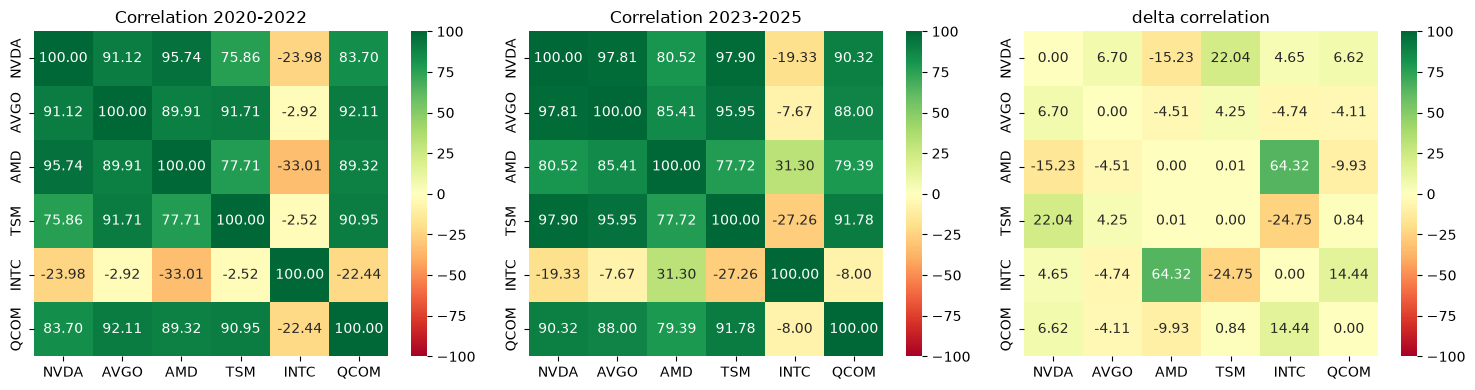

In [349]:
def filter_period(df:pd.DataFrame, begin:str, end:str) -> pd.DataFrame:
    return df[(df["Date"] >= begin) & (df["Date"] <= end)]

cat2_20_22:pd.DataFrame = pd.DataFrame()
for tickers in CAT2:
    cat2_20_22[tickers] = filter_period(TRAINING_DATAS[tickers], '2020-01-01', '2021-12-30')["Close"]

cat2_23_25:pd.DataFrame = pd.DataFrame()
for tickers in CAT2:
    cat2_23_25[tickers] = filter_period(TRAINING_DATAS[tickers], '2023-01-01', '2024-12-30')["Close"]


fig, ax = plt.subplots(1, 3, figsize=(15,4))
# display(cat2_20_22.head())
# display(cat2_20_22.corr()*100)

sb.heatmap(
    cat2_20_22.corr()*100,
    annot=True,
    cmap="RdYlGn",
    vmax=100,
    vmin=-100,
    fmt=".2f",
    ax=ax[0]
)
ax[0].set_title("Correlation 2020-2022")

sb.heatmap(
    cat2_23_25.corr()*100,
    annot=True,
    cmap="RdYlGn",
    vmax=100,
    vmin=-100,
    fmt=".2f",
    ax=ax[1]
)
ax[1].set_title("Correlation 2023-2025")


sb.heatmap(
    cat2_23_25.corr()*100 - cat2_20_22.corr()*100,
    annot=True,
    cmap="RdYlGn",
    vmax=100,
    vmin=-100,
    fmt=".2f",
    ax=ax[2]
)
ax[2].set_title("delta correlation")

plt.tight_layout()
plt.show()

In [350]:
def calculate_returns(df:pd.DataFrame) -> pd.DataFrame:
    df["percent_returns"] = (df["Close"] - df["Open"]) / df["Open"]
    return df

def calculate_swings(df:pd.DataFrame) -> pd.DataFrame:
    df["percent_swing"] = (df["High"] - df["Low"]) / df["Low"]
    return df

In [351]:
def process_data(data:dict[str, pd.DataFrame]) -> dict[str, pd.DataFrame]:
    for tickers in TICKERS:
        data[tickers] = calculate_returns(data[tickers])
        data[tickers] = calculate_swings(data[tickers])
    return data

TRAINING_DATAS = process_data(TRAINING_DATAS)
TESTINGS_DATAS = process_data(TESTINGS_DATAS)
display(TRAINING_DATAS[TICKERS[0]].head())

,Date,Open,High,Low,Close,Volume,percent_returns,percent_swing
0,2016-10-17,26.831687,26.948315,26.705909,26.881998,94499600,0.001875,0.009077
1,2016-10-18,27.026069,27.032930,26.859128,26.863703,98214000,-0.006008,0.006471
2,2016-10-19,26.813389,26.930020,26.024425,26.783661,80138400,-0.001109,0.034798
3,2016-10-20,26.724205,26.843121,26.603002,26.769941,96503200,0.001711,0.009026
4,2016-10-21,26.712767,26.735637,26.591564,26.664743,92770800,-0.001798,0.005418


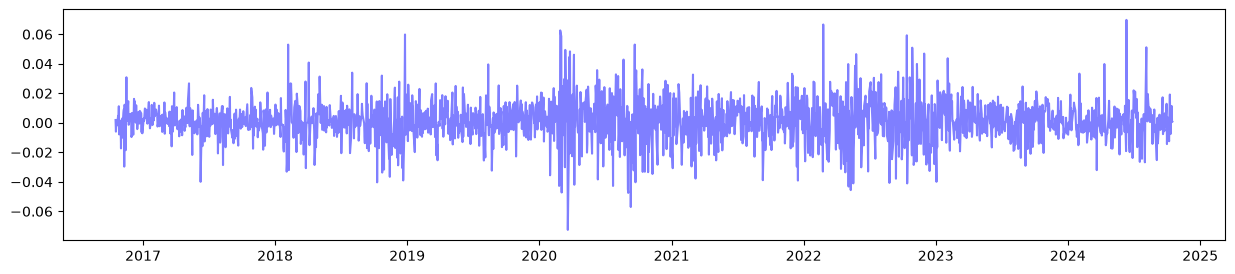

In [352]:
plt.figure(figsize=(15,3))
plt.plot(TRAINING_DATAS[TICKERS[0]].Date, TRAINING_DATAS[TICKERS[0]].percent_returns, color='b', label=tickers, alpha=0.5)


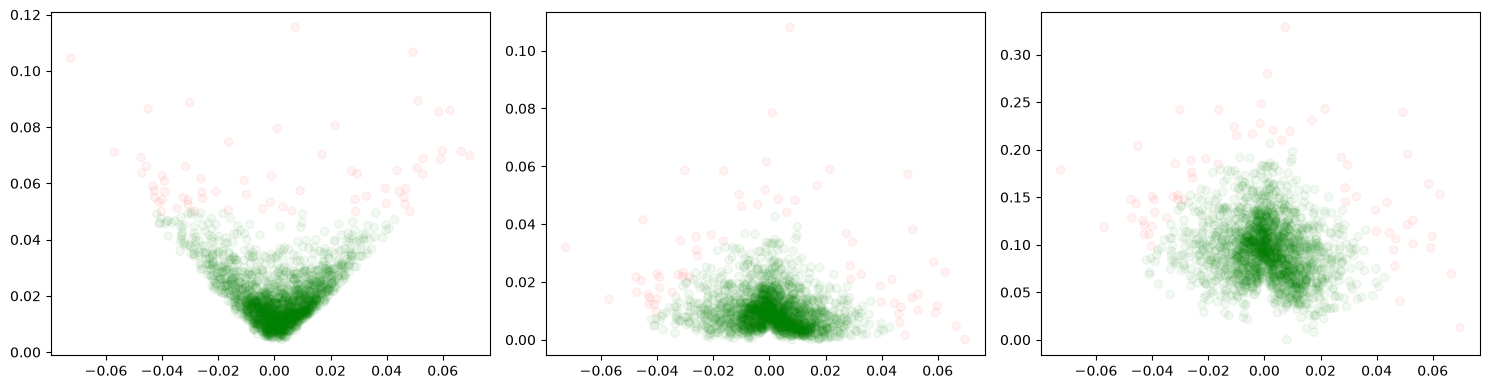

In [353]:
x = TRAINING_DATAS[TICKERS[0]].percent_returns
y = TRAINING_DATAS[TICKERS[0]].percent_swing

colors = ["r" if v > 0.05 else "g" for v in y]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].scatter(x, y, color=colors, alpha=0.05)
ax[1].scatter(x, y - abs(x), color=colors, alpha=0.05)
ax[2].scatter(x, (y - abs(x))**(1/2), color=colors, alpha=0.05)
plt.tight_layout()

,0d,1d,2d,3d,4d,5d,6d,7d,8d,9d
0,0.001875,0.001193,-0.001790,-0.002301,-0.006222,0.002727,0.007841,-0.014830,-0.024291,-0.030768
1,-0.006008,-0.008969,-0.009477,-0.013370,-0.004485,0.000592,-0.021916,-0.031308,-0.037739,-0.039262
2,-0.001109,-0.001620,-0.005544,0.003412,0.008529,-0.014158,-0.023625,-0.030106,-0.031642,-0.049126
3,0.001711,-0.002225,0.006760,0.011895,-0.010868,-0.020366,-0.026870,-0.028410,-0.045953,-0.045097
4,-0.001798,0.007191,0.012328,-0.010444,-0.019947,-0.026453,-0.027994,-0.045544,-0.044688,-0.054928
...,...,...,...,...,...,...,...,...,...,...
1981,-0.025290,-0.033691,-0.026996,-0.033822,-0.033428,-0.036928,-0.025771,-0.025290,-0.026471,-0.053511
1982,-0.003654,0.003248,-0.003790,-0.003383,-0.006993,0.004511,0.005008,0.003790,-0.024091,-0.021971
1983,0.003384,-0.003655,-0.003249,-0.006858,0.004647,0.005144,0.003926,-0.023959,-0.021838,-0.004241
1984,-0.013976,-0.013574,-0.017147,-0.005760,-0.005269,-0.006474,-0.034070,-0.031971,-0.014557,0.021969


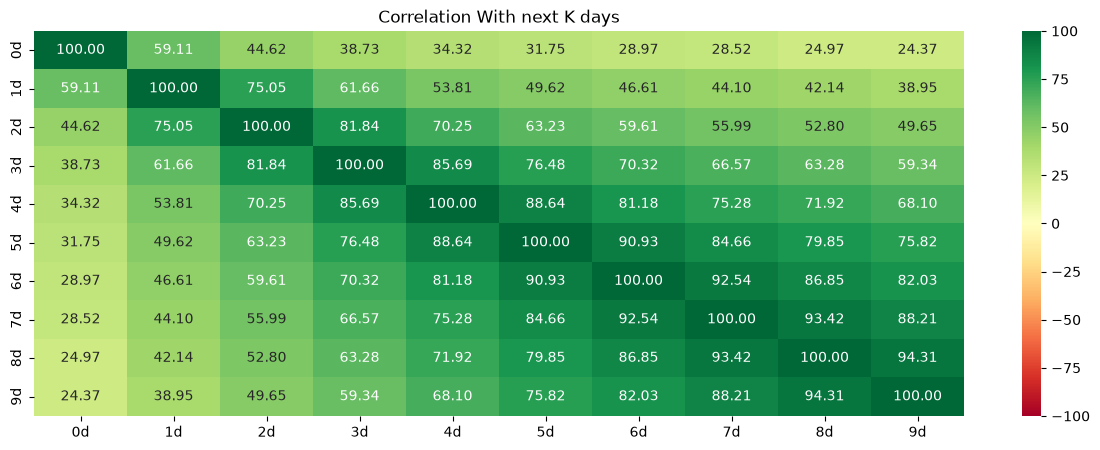

In [362]:
def calculate_future(df:pd.DataFrame, days:int) -> pd.DataFrame:
    df["future_" + str(days) + "day_close"] = df["Close"].shift(-days)
    df["percent_future_" + str(days) + "day"] = (df["future_" + str(days) + "day_close"] - df["Open"]) / df["Open"]
    return df

for tickers in TICKERS:
    TRAINING_DATAS[tickers] = calculate_future(TRAINING_DATAS[tickers], 1)
    TRAINING_DATAS[tickers] = calculate_future(TRAINING_DATAS[tickers], 2)
    TRAINING_DATAS[tickers] = calculate_future(TRAINING_DATAS[tickers], 3)
    TRAINING_DATAS[tickers] = calculate_future(TRAINING_DATAS[tickers], 4)
    TRAINING_DATAS[tickers] = calculate_future(TRAINING_DATAS[tickers], 5)
    TRAINING_DATAS[tickers] = calculate_future(TRAINING_DATAS[tickers], 6)
    TRAINING_DATAS[tickers] = calculate_future(TRAINING_DATAS[tickers], 7)
    TRAINING_DATAS[tickers] = calculate_future(TRAINING_DATAS[tickers], 8)
    TRAINING_DATAS[tickers] = calculate_future(TRAINING_DATAS[tickers], 9)
    TRAINING_DATAS[tickers].dropna(inplace=True, how="any")
# display(TRAINING_DATAS[TICKERS[0]].head())

future_df:pd.DataFrame = TRAINING_DATAS[TICKERS[0]][
    [
        "percent_returns",
        "percent_future_" + str(  1) + "day", 
        "percent_future_" + str(  2) + "day",
        "percent_future_" + str(  3) + "day",
        "percent_future_" + str(  4) + "day",
        "percent_future_" + str(  5) + "day",
        "percent_future_" + str(  6) + "day",
        "percent_future_" + str(  7) + "day",
        "percent_future_" + str(  8) + "day",
        "percent_future_" + str(  9) + "day",
    ]
]

future_df = future_df.rename(columns={"percent_returns" : "0d"})
future_df = future_df.rename(columns={"percent_future_" + str(  1) + "day" : "1d"})
future_df = future_df.rename(columns={"percent_future_" + str(  2) + "day" : "2d"})
future_df = future_df.rename(columns={"percent_future_" + str(  3) + "day" : "3d"})
future_df = future_df.rename(columns={"percent_future_" + str(  4) + "day" : "4d"})
future_df = future_df.rename(columns={"percent_future_" + str(  5) + "day" : "5d"})
future_df = future_df.rename(columns={"percent_future_" + str(  6) + "day" : "6d"})
future_df = future_df.rename(columns={"percent_future_" + str(  7) + "day" : "7d"})
future_df = future_df.rename(columns={"percent_future_" + str(  8) + "day" : "8d"})
future_df = future_df.rename(columns={"percent_future_" + str(  9) + "day" : "9d"})

display(future_df)
plt.figure(figsize=(15,5))
plt.title("Correlation With next K days")

sb.heatmap(
    future_df.corr("spearman")*100,
    annot=True,
    cmap="RdYlGn",
    vmax=100,
    vmin=-100,
    fmt=".2f"
)
# ax[2].set_title("delta correlation")
plt.show()

future_df["Open"] = TRAINING_DATAS[TICKERS[0]]["Open"]

## Training on Knowing K days and predicting for N days (future_df)

0.8520059754085525

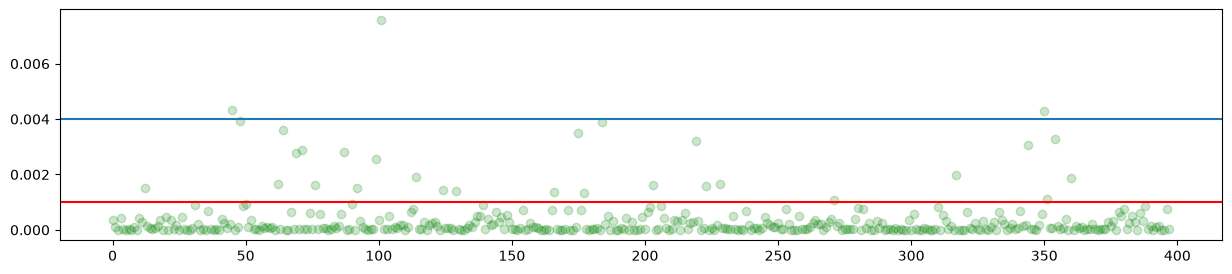

In [363]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# train on knowing all 0 to 6 days and predict 7th day
X = future_df[["Open", "0d", "6d"]]
y = future_df["7d"]

X1, X2, y1, y2 = train_test_split(X, y, test_size=0.2)

model = LinearRegression(n_jobs=-1)
model.fit(X1, y1)
display(model.score(X2, y2))
y_ = model.predict(X2)

plt.figure(figsize=(15,3))
plt.scatter(range(len(y2)), (y2-y_)**2, color='g', alpha=0.2)
plt.axhline(y=0.004)
plt.axhline(y=0.001, color='r')
# plt.bar(range(len(y_)), y_, color="g", alpha=0.8)

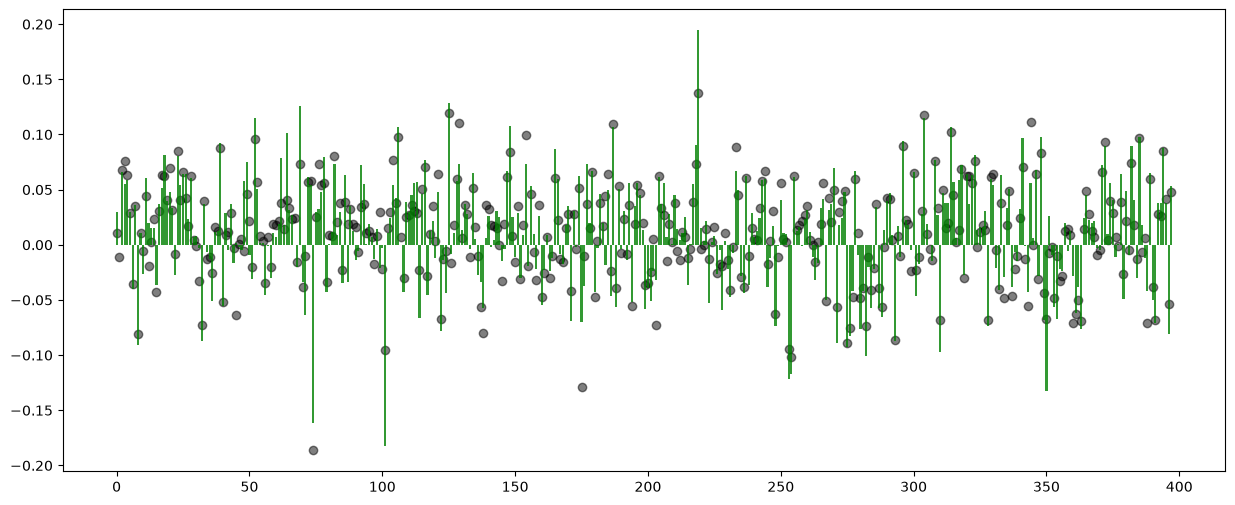

In [364]:
plt.figure(figsize=(15,6))
plt.scatter(range(len(y_)), y_, color='black', alpha=0.5)
plt.bar(range(len(y2)), y2, color='g', alpha=0.8)
plt.show()

In [365]:
display(model.coef_)

array([-5.88648229e-06,  1.31614456e-01,  9.76215925e-01])

The the high value correlation of k-1, k for high value of k is due to lack of movement in percent_returns for long periods and is just an artifact, it is as good as correlation betweeen day 0 and day +1 if we can somehow make sure that consicutive percent_returns are averaged over n days.

## Training on Intraday Closing Price

Given Open, High, Low, Volume -> Predict Closing Price

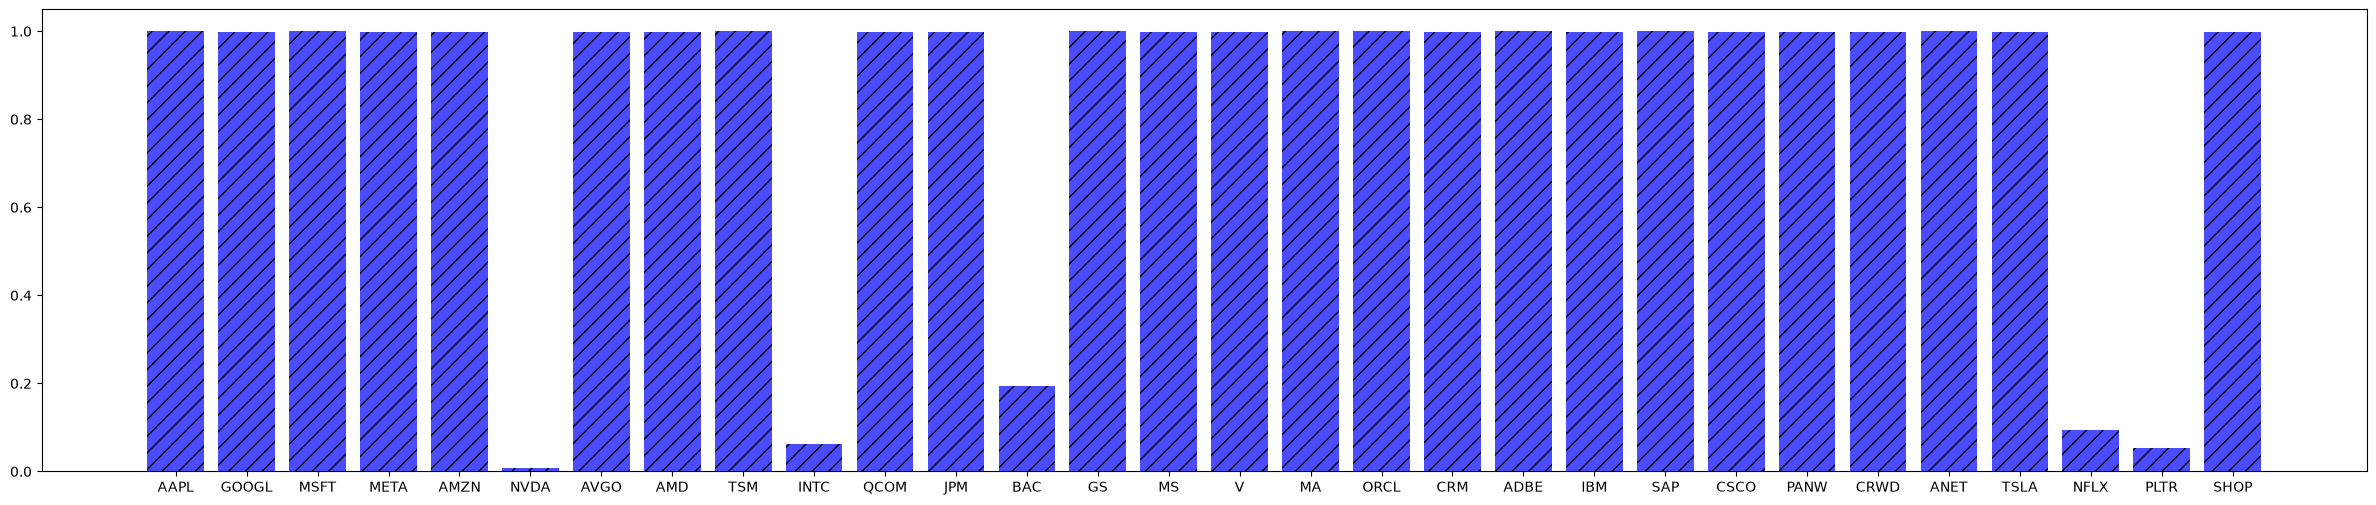

In [371]:
lr_accuracy:list[float] = []
for ticker in TICKERS:
    X:pd.DataFrame = TRAINING_DATAS[ticker][["Open", "High", "Low", "Volume"]]
    y:pd.Series    = TRAINING_DATAS[ticker]["Close"]

    X1, X2, y1, y2 = train_test_split(X, y, test_size=0.2)

    model:LinearRegression = LinearRegression(n_jobs=-1)
    model.fit(X1, y1)
    accuracy = float(model.score(X2, y2))
    lr_accuracy.append(accuracy)

plt.figure(figsize=(30,6))
plt.bar(TICKERS, lr_accuracy, color='b', hatch="//", alpha=0.7)
plt.show()

'High Voatility and Variance in Low-High leads to less Accuracy'

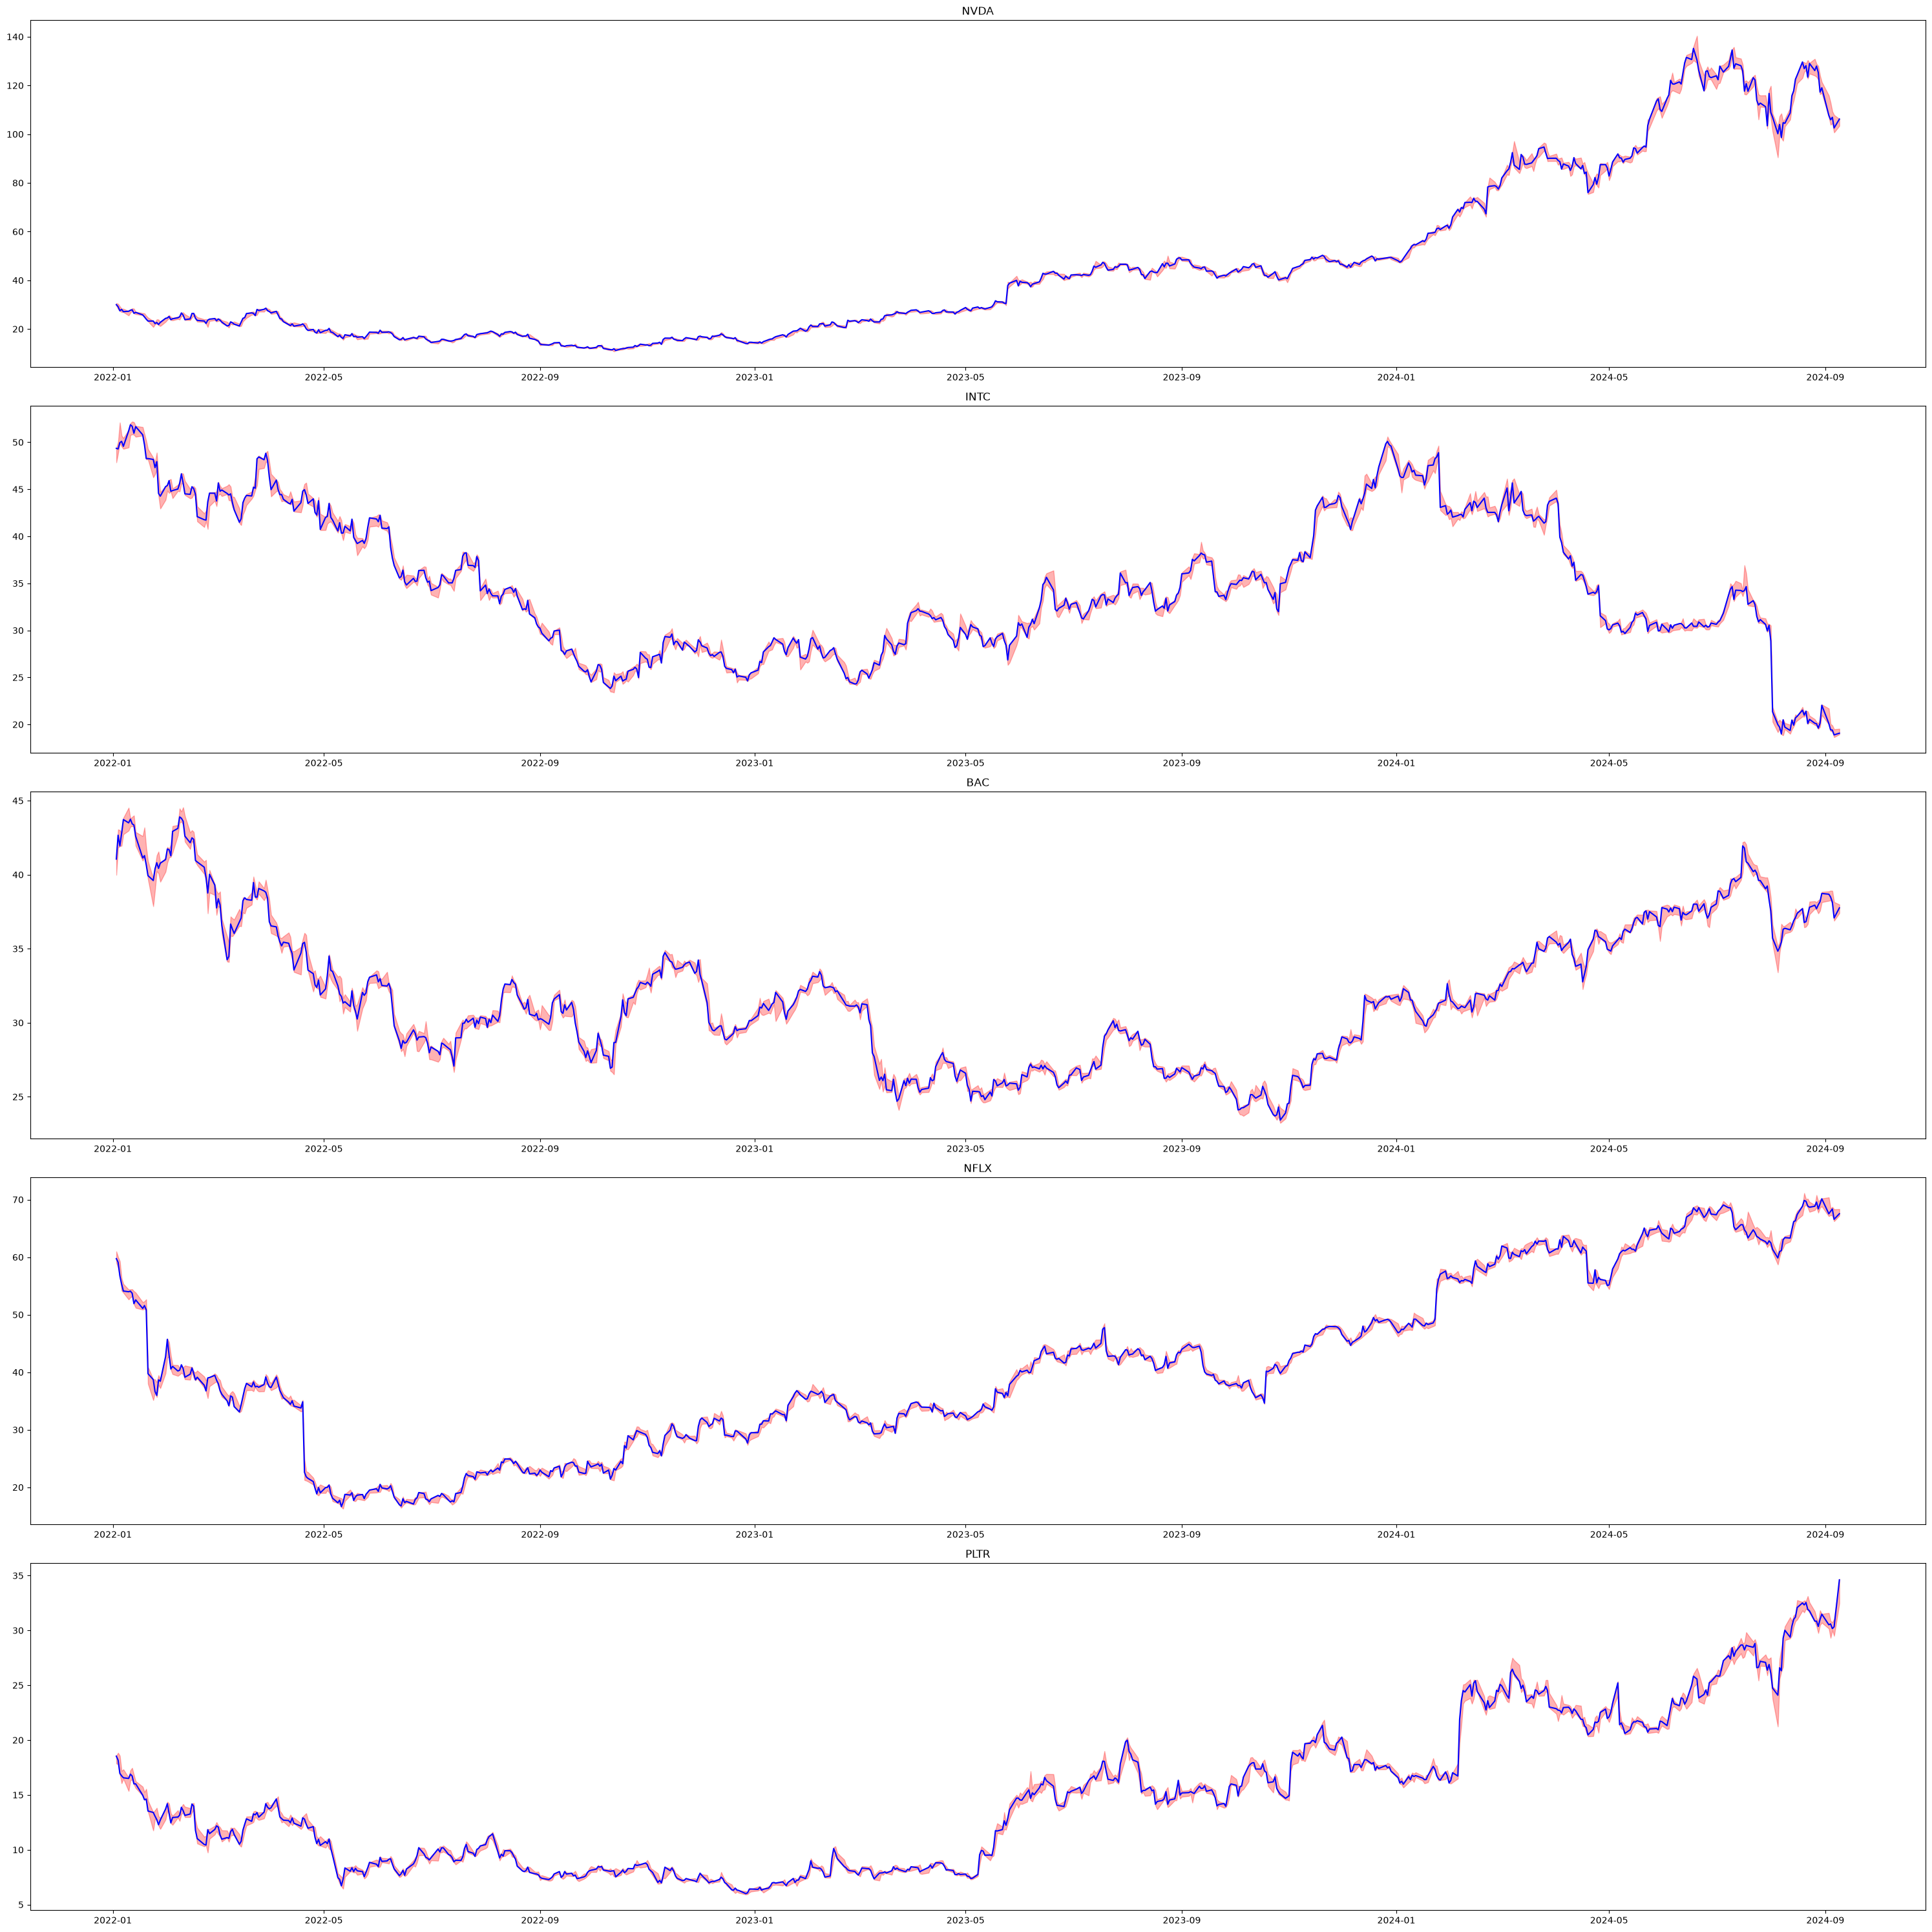

In [ ]:
bad_accuracies: list[str] = []
for accuracy, ticker in zip(lr_accuracy, TICKERS):
    if accuracy < 0.5:
        bad_accuracies.append(ticker)

fig, ax = plt.subplots(len(bad_accuracies), 1, figsize=(30, 6*len(bad_accuracies)))
for i in range(len(bad_accuracies)):
    df:pd.DataFrame = filter_period(TRAINING_DATAS[bad_accuracies[i]], '2022-01-01', "2026")
    ax[i].fill_between(df["Date"], df["High"], df["Low"], color='r', alpha=0.3)
    ax[i].plot(df["Date"], df["Close"], color="b")
    ax[i].set_title(bad_accuracies[i])
plt.tight_layout()

display("High Voatility and Variance in Low-High leads to less Accuracy")

Cross intraday value prediction, Training for intraday correlation on stock 1 and predicting behaviour of stock 2

In [389]:
Xa = TRAINING_DATAS["AAPL"][["Open", "High", "Low", "Volume"]]
ya = TRAINING_DATAS["AAPL"]["Close"]

Xb = TRAINING_DATAS["MSFT"][["Open", "High", "Low", "Volume"]]
yb = TRAINING_DATAS["MSFT"]["Close"]

modelA:LinearRegression = LinearRegression(n_jobs=-1)
modelB:LinearRegression = LinearRegression(n_jobs=-1)

modelA.fit(Xa, ya)
modelB.fit(Xb, yb)

display(modelA.coef_, modelB.coef_)
display(modelA.score(Xb, yb))
display(modelB.score(Xa, ya))


array([ 3.33305755e-01,  3.37731497e-01,  3.28914295e-01, -6.88161195e-10])

array([ 3.33456096e-01,  3.36508718e-01,  3.30031890e-01, -1.06950897e-08])

0.9996330440827559

0.9993354446396667

Can intraday value prediction, coorectly predict value for unseen data of same stock

array([ 3.33305755e-01,  3.37731497e-01,  3.28914295e-01, -6.88161195e-10])

0.9961509932326816

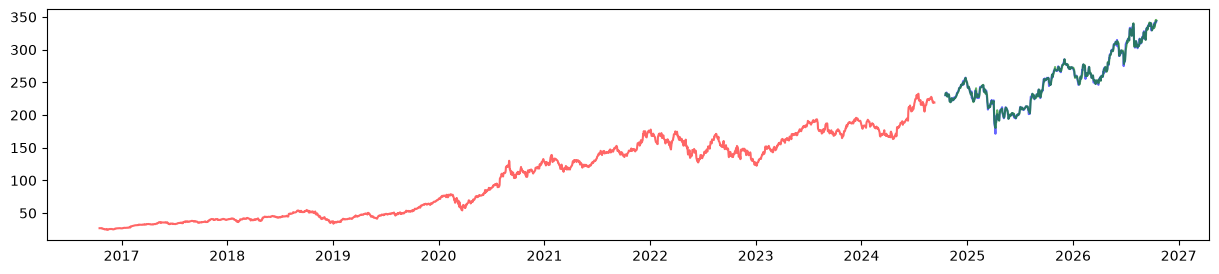

In [436]:
Xa = TRAINING_DATAS["AAPL"][["Open", "High", "Low", "Volume"]]
ya = TRAINING_DATAS["AAPL"]["Close"]

Xb = TESTINGS_DATAS["AAPL"][["Open", "High", "Low", "Volume"]]
yb = TESTINGS_DATAS["AAPL"]["Close"]

model:LinearRegression = LinearRegression(n_jobs=-1)
model.fit(Xa, ya)

display(model.coef_)
display(model.score(Xb, yb))

y_ = model.predict(Xb)

plt.figure(figsize=(15, 3))
Xxa = TRAINING_DATAS["AAPL"]["Date"]
Xxb = TESTINGS_DATAS["AAPL"]["Date"]
plt.plot(Xxa, ya, color="r", alpha=0.6)
plt.plot(Xxb, yb, color="b", alpha=0.6)
plt.plot(Xxb, y_, color="g", alpha=0.6)
plt.show()

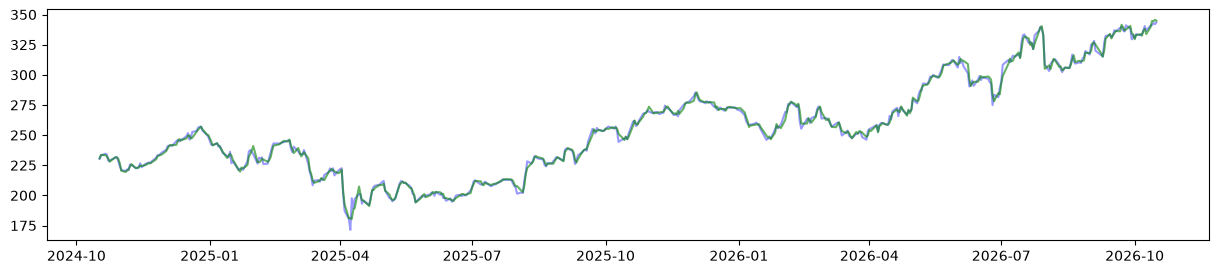

In [437]:
plt.figure(figsize=(15, 3))
# plt.fill_between(Xxb, Xb["Low"], Xb["High"], color="r", alpha=0.4)
plt.plot(Xxb, yb, color="b", alpha=0.4)
plt.plot(Xxb, y_, color="g", alpha=0.6)
plt.show()

Not that big of a deal as model knows that closing price just stays between low and high and evidently uses 0.3 x open + 0.3 x low + 0.3 x high. It cant be too far off because it is predicting what it already knows (the range)

In [429]:
# Normalize volume
# Use history
# Use moving average etc

## Testing